# Bayes-formula

 $$𝑃(𝐴|𝐵) = \frac{𝑃(𝐵|𝐴) * 𝑃(𝐴)}{𝑃(𝐵)}$$

 $$𝑃(𝐵|𝐴) = \frac{𝑃(𝐴|𝐵) * 𝑃(𝐵)}{𝑃(𝐴)}$$

>Az előző példában: mekkora eséllyel dobtunk nem hatost, feltéve, hogy párost dobtunk?

 $$𝑃(𝐵|𝐴) = \frac{2/5 * 5/6}{1/2} = \frac{2}{3} $$

- **ami a következőképpen ellenőrizhető:** páros dobás esetén a lehetséges értékek: 2, 4, 6, azaz kétharmad eséllyel lesz nem hatos

- **Használata**: ha az egyik irányú feltételes valószínűség kiszámítása sokkal könnyebb mint a másik, de nekünk a másikra van szükség


## Bayes-formula a gépi tanulásban 

Elmagyarázza, hogyan frissíthető egy hipotézis valószínűsége **új bizonyítékok észlelésekor**. 

A korábbi **ismereteket adatokkal ötvözi**, hogy jobb döntéseket hozhasson **bizonytalanság esetén**, és a gépi tanulásban a Bayes-következtetés alapját képezi.

- Hatékonyan **kezeli a bizonytalanságot és a zajos adatokat**

- Támogatja a **modell-előrejelzések** valószínűségi értelmezését

- Lehetővé teszi a tanulást még **korlátozott adatokkal is**

- Kulcsszerepet játszik a valós alkalmazásokban, például a**kockázatelemzésben és a diagnózisban**



### Bayes-tétel elemei

- **Poszterior valószínűség** $P(A \mid B)$: Az $A$ hipotézis frissített valószínűsége a $B$ bizonyíték megismerése után.
- **Likelihood (Valószerűség)** $P(B \mid A)$: A $B$ bizonyíték megfigyelésének a valószínűsége, feltéve, hogy az $A$ hipotézis igaz.
- **Prior valószínűség** $P(A)$: Az $A$ hipotézis kezdeti valószínűsége bármilyen bizonyíték megfigyelése előtt.
- **Bizonyíték (Marginális valószínűség)** $P(B)$: A $B$ bizonyíték megfigyelésének a teljes valószínűsége, amely normalizáló tényezőként szolgál.



1. A szükséges könyvtárak telepítése és importálása a gépi tanulási modellezéshez és a vizualizációhoz
> - A pandas-t adatkezelésre használják
> - A scikit-learn gépi tanulási algoritmusokat és értékelési metrikákat biztosít
> - A matplotlib és a seaborn a vizualizációhoz használatos.

   Label                                            Message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...
Accuracy: 98.39%


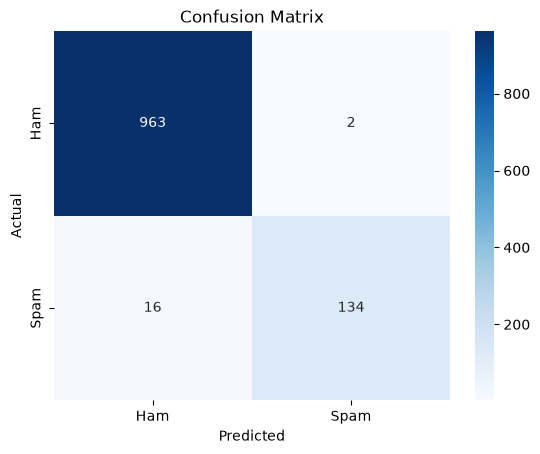

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       965
           1       0.99      0.89      0.94       150

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115

Message: 'Congratulations! You won a free ticket.' => Prediction: Spam
Message: 'Hey, are we still meeting today?' => Prediction: Ham


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 2 Az adatkészlet betöltése és előfeldolgozása
df = pd.read_csv("files/spam.csv", encoding='latin-1')[['v1', 'v2']] # csak két oszlopot tart meg

# Kategóriacímkék konvertálása numerikus értékekké
df.columns = ['Label', 'Message']
df['Label'] = df['Label'].map({'ham': 0, 'spam': 1})

print(df.head())


# 3 Jellemzők és célváltozó szétválasztása (0 Ham, 1  Spam )
X = df['Message'] # Jellemzők, bemeneti adatok 
y = df['Label'] # Célváltozó, cimke, kimenet 

# 4 Adatok felosztása betanító (80%) és tesztelő (20%) halmazokra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42            # A random_state biztosítja az ismételhetőséget
)

# 5. Szöveges adatok konvertálása numerikus formába

vectorizer = CountVectorizer()      #szótárt hoz létre, szöveget konvertál szógyakorisági vektorokká
X_train_vec = vectorizer.fit_transform(X_train) # megtanulja és átalakítja
X_test_vec = vectorizer.transform(X_test) # alkalmazza a tesztadatokra 


# 6. A naiv Bayes-modell betanítása vektorizált betanítási adatok használatával

nb_model = MultinomialNB() #szógyakoriságokhoz használt osztályozó
nb_model.fit(X_train_vec, y_train) # megtanulja összefüggni a szavak előfordulását

# 7  Előrejelzések készítése tesztadatok alapján, használja spam vagy amatőr üzenetek előrejelzésére
y_pred = nb_model.predict(X_test_vec)

 # 8. A modell teljesítményének értékelése
'''
- A pontosság kiszámítása az általános teljesítmény mérésére
- Konfúziós mátrix generálása részletes elemzéshez
- Kijelző pontossága, visszahívása és F1-pontszáma
'''

# százalékos pontosság (hány üzenetet talált el helyesen a modell összesen).
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

#Egy hőtérképpel (seaborn) szemlélteti, hogy hol tévedett a modell 
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred))



# 9.  A modell tesztelése új üzeneteken
#A betanított modell használata a láthatatlan üzenetek osztályozására
# Új üzenetek vektorizálása ugyanazzal a szókinccsel

new_messages = [
    "Congratulations! You won a free ticket.",
    "Hey, are we still meeting today?"
]

new_vec = vectorizer.transform(new_messages) # vektorrá alakítás
predictions = nb_model.predict(new_vec) #egy számsorozat lesz, pl [1, 0] = első üzenet Spam (1), a második pedig Ham (0).

for msg, pred in zip(new_messages, predictions): #Összepárosítja az eredeti szöveget a modell tippjével
    label = "Spam" if pred == 1 else "Ham"
    print(f"Message: '{msg}' => Prediction: {label}")

## Alkalmazásai a gépi tanulásban

A **bizonytalanság kezelésének** és az előzetes ismeretek beépítésének képességét teszi lehetővé, hogy a modellek pontos előrejelzéseket tegyenek **még hiányos vagy zajos adatok esetén is**, mint például:

- 1. **Naiv Bayes-osztályozó**: Ez egy egyszerű valószínűségi modell, amely a Bayes-tételen alapul, és jellemzőfüggetlenséget feltételez, így hatékony és eredményes olyan feladatokhoz, mint a szövegosztályozás és a spamészlelés.

- 2. **Bayes-optimális osztályozó**: **Elméleti modell**, amely adott jellemzők esetén a legmagasabb posterior valószínűséggel rendelkező osztályt jósolja meg, ami a lehető legjobb osztályozási pontosságot jelenti. A modell a Bayes-formulát használja a valószínűségek frissítésére az új bizonyítékok alapján.

$$\hat{y} = {\arg\max}\underset{y} \, P(y \mid x)$$

**y^ - Előrejelzett osztálycímke**

**y - Lehetséges osztálycímke**

**x - Bemeneti jellemzővektor**

**P(y ∣ x) - Az adott osztályú jellemzők utólagos valószínűsége**

- 3. **Bayes-optimalizálás:** Olyan technika, amely hatékonyan megtalálja a **költségesen kiértékelhető függvények maximumát **vagy minimumát egy valószínűségi modell,** gyakran Gauss-folyamat** segítségével. 
Iteratívan választja ki a legígéretesebb pontokat a kiértékeléshez, így ideális olyan feladatokhoz, mint a gépi tanulásban a **hiperparaméterek finomhangolása**  (milyen tanulási sebességet állítsunk be).

- 4. **Bayes-i hiedelemhálózatok (BBN-ek)**: Valószínűségi grafikus modellek, amelyek a változókat és azok feltételes függőségeit **irányított aciklikus gráf (DAG)** segítségével ábrázolják. Széles körben alkalmazzák őket a kockázatelemzésben, a diagnosztikában és a döntéshozatalban. *(pl. Dohányzás $\rightarrow$ Tüdőbetegség)*